### Rechtsrum in Rechthausen – Lösung Schritt für Schritt

*35. Bundeswettbewerb Informatik (2016/2017), 2. Runde, Aufgabe 2*

Eine Statistik der Polizei von Rechthausen hat gezeigt, dass eine Vielzahl von Autounfällen durch inkorrektes Linksabbiegen verursacht
wird. Der Bürgermeister von Rechthausen hat deshalb beschlossen, das Linksabbiegen per Dekret zu untersagen. Autofahrer sollen in
Rechthausen nur noch geradeaus fahren oder rechts abbiegen dürfen. Diese Entscheidung führt zu viel Unmut der Bewohner von Rechthausen.
Sie befürchten, sich dann in der Stadt nicht mehr zurechtzufinden. Du möchtest Abhilfe schaffen und ein Navigationssystem erstellen, das
nur Routen vorschlägt, bei denen nicht links abgebogen werden muss. Dein System erhält als Eingabe ein Straßenverzeichnis. Dieses
besteht aus einer Menge V von Kreuzungen mit ihren jeweiligen Koordinaten sowie der Menge E von denjenigen Paaren von Kreuzungen, die
direkt durch Straßenabschnitte verbunden sind. Da Rechthausen eine moderne Stadt ist, haben die Straßen keinerlei Kurven. Das
Straßennetz von Rechthausen könnte zum Beispiel so aussehen (alles, was in Rechthausen als Kreuzung angesehen wird, ist durch einen
Buchstaben gekennzeichnet):

*(Bild: ein Straßennetz mit den Kreuzungen A bis I. Es ist das Beispiel `rechthausen1.txt`; wir zeichnen es in Schritt 1.)*

1. In der üblichen Situation, in der sich zwei Straßen im rechten Winkel kreuzen, ist es klar, was unter Linksabbiegen zu verstehen ist.
   Formuliere eine allgemeinere Definition des Linksabbiegens. Sie soll auch dann benutzt werden können, wenn die Anzahl d der
   Richtungen, aus denen man sich einer Kreuzung nähern kann, nicht vier ist oder der Winkel zwischen einer Richtung und der Richtung
   unmittelbar rechts von ihr nicht immer 90° ist. Am Wichtigsten ist, dass die Definition in jeder Situation angewendet werden kann und
   eine eindeutige Entscheidung herbeiführt, ob es sich beim Fahren von einem Straßenabschnitt über eine Kreuzung in einen nächsten
   Straßenabschnitt um Linksabbiegen handelt oder nicht. Versuche außerdem, mit deiner Definition die ursprüngliche Bedeutung des
   Linksabbiegens als besonders unfallträchtiges Verkehrsmanöver zu erhalten. Deine Definition soll insbesondere in den Fällen d = 1 (das
   Ende einer Sackgasse) und d = 2 sinnvolle Antworten liefern.

   Im obigen Beispiel sollten beispielsweise die Routen DADEF sowie GCB und FEBC erlaubt sein, die Routen DEB und IGF dagegen nicht.
2. Veranschauliche deine Definition durch geeignete Beispiele.
3. Schreibe ein Programm, das einen kürzesten Weg ohne Linksabbiegen von einer Startkreuzung S zu einer Zielkreuzung T auf beliebigen
   Straßen findet, falls T von S aus überhaupt erreicht werden kann. Dabei sollst du die Weglänge auf zwei verschiedene Arten messen: zum
   einen nach der Anzahl, zum anderen nach der Gesamtlänge der auf dem Weg durchfahrenen Straßenabschnitte. Im obigen Beispiel: Was ist
   ein kürzester Weg ohne Linksabbiegen von A nach C? Und von H nach A?
4. Erweitere dein Programm so, dass es für ein gegebenes Straßenverzeichnis ermittelt, ob jede Kreuzung von jeder anderen Kreuzung aus
   ohne Linksabbiegen erreicht werden kann.
5. Erweitere dein Programm so, dass es ein Paar von Start- und Zielkreuzung ermittelt, für das das Verbot des Linksabbiegens die
   Weglänge um den größtmöglichen Faktor erhöht. Wende auch hier beide Weglängenmaße an.
6. Wende dein Programm auf die Beispiele an, die du auf der BWINF-Webseite zu dieser Runde findest.

#### Beispieldaten

Im Ordner `beispieldaten` steht nur `rechthausen1.txt`, das Netz aus der Aufgabe. Zeilen, die mit `#` beginnen, sind Kommentare. Dann
kommen die Anzahl der Kreuzungen und der Straßenabschnitte, je Zeile eine Kreuzung „Name x y“, noch einmal die Anzahl der
Straßenabschnitte und je Zeile ein Straßenabschnitt „Name Name“. Weitere Beispiele stammten damals aus der Community und liegen nicht
vor. Darum bauen wir eigene: zwei kleine Netze im Ordner `eigene_testdaten` (gleiches Format) und Zufallsstädte, die das Notebook selbst
erzeugt.

## Was dir bei dieser Aufgabe hilft

**Algorithmische Kenntnisse**
- **Winkel aus Koordinaten:** Die Richtung einer Strecke berechnet man mit dem Arkustangens. Winkel rechnet man **modulo 360**: 370°
  und 10° sind dieselbe Richtung, −90° und 270° auch.
- **Graph als Wörterbuch:** Zu jeder Kreuzung speichern wir die Liste ihrer Nachbarn und ihre Koordinaten.
- **Zustände statt Kreuzungen:** Ob ich an einer Kreuzung in eine Straße einbiegen darf, hängt davon ab, **woher** ich komme. Wir suchen
  deshalb nicht über Kreuzungen, sondern über Zustände „ich bin gerade von a nach b gefahren“.
- **Breitensuche:** findet den Weg mit den wenigsten Straßenabschnitten.
- **Algorithmus von Dijkstra:** findet den Weg mit der kleinsten Gesamtlänge, wenn die Straßen verschieden lang sind.
- **Kürzeste Wege zwischen allen Paaren:** eine Suche von jeder Kreuzung aus.

**Nützliche Funktionen und Bibliotheken**
- `math.atan2(dy, dx)` gibt den Winkel der Richtung `(dx, dy)` im Bogenmaß, gemessen gegen den Uhrzeigersinn ab der x-Achse (von −π bis
  π); `math.degrees` rechnet ihn in Grad um. `math.hypot(dx, dy)` ist die Länge √(dx² + dy²).
- `x % 360` ist in Python auch für negative `x` eine Zahl von 0 bis unter 360, zum Beispiel `-90 % 360 == 270`.
- `collections.deque` mit `append` und `popleft` als Warteschlange für die Breitensuche.
- `heapq.heappush(liste, eintrag)` und `heapq.heappop(liste)`: eine **Prioritätswarteschlange**; `heappop` holt immer den kleinsten
  Eintrag heraus. Einträge sind bei uns Tupel, die zuerst nach ihrem ersten Wert verglichen werden (dem Abstand).
- `matplotlib.pyplot` zum Zeichnen, `random.Random(zahl)` für Zufallsstädte, die bei jedem Lauf gleich aussehen.

## Die Idee in Worten

1. **Was heißt „links abbiegen“? (Teil 1)** Wir übernehmen die Definition aus den Lösungshinweisen. Sie geht vom Unfall aus: Gefährlich
   ist es, die Spur des **Gegenverkehrs** zu kreuzen.
   - Stell dir vor, du stehst mitten in der Kreuzung und schaust in die Straße, aus der du gekommen bist. Nun drehst du dich **im
     Uhrzeigersinn**. Für jede Straße der Kreuzung merkst du dir, um wie viel Grad du dich drehen musst, bis du in sie hineinschaust: ihr
     **Drehwinkel** (die Straße, aus der du kommst, hat den Drehwinkel 0).
   - Der **Gegenverkehr** kommt aus der Straße, die der Herkunftsstraße am stärksten entgegengesetzt ist. Das ist die Straße mit dem
     größten **Differenzwinkel**; der Differenzwinkel ist der kleinere der beiden Winkel zwischen den Straßen, also min(w, 360° − w) bei
     Drehwinkel w. Bei einer gewöhnlichen Kreuzung ist das die Straße geradeaus (Drehwinkel 180°).
   - Haben zwei Straßen denselben größten Differenzwinkel (wie bei einer T-Kreuzung, in die man von unten kommt), denken wir uns den
     Gegenverkehr genau gegenüber, beim Drehwinkel 180°.
   - **Verboten** sind alle Straßen, die beim Drehen **vor** dem Gegenverkehr kommen (kleinerer Drehwinkel). Um in sie zu gelangen,
     müsste man die Spur des Gegenverkehrs kreuzen. **Erlaubt** sind die Straße des Gegenverkehrs selbst und alle danach.

   Das passt zu den Sonderfällen: In einer **Sackgasse** (d = 1) ist die einzige Straße die Herkunftsstraße selbst, ihr Drehwinkel 0 ist
   auch der des Gegenverkehrs, also ist **Wenden erlaubt**. Bei **d = 2** ist die andere Straße der Gegenverkehr und erlaubt, egal wie
   der Knick aussieht; das Wenden (Drehwinkel 0) ist verboten. Allgemein ist Wenden nur in der Sackgasse erlaubt.
2. **Beispiele (Teil 2):** acht kleine Kreuzungen als Bild.
3. **Kürzeste Wege (Teil 3):** Für jede Fahrt „von a nach b“ berechnen wir einmal die Liste der Kreuzungen c, zu denen man danach
   weiterfahren darf. Über diese Zustände suchen wir mit der Breitensuche (Anzahl der Straßenabschnitte) und mit Dijkstra (Länge).
4. **Erreichbarkeit (Teil 4):** eine Suche von jeder Kreuzung aus. Dabei stoßen wir auf ein Netz, in dem das Verbot Verbindungen
   unmöglich macht, obwohl die Lösungshinweise das Gegenteil behaupten.
5. **Größter Faktor (Teil 5):** von jeder Kreuzung aus die kürzesten Wege mit und ohne Verbot vergleichen.
6. **Alle Beispiele (Teil 6), für Neugierige** und **zum Schluss** ein MiniZinc-Modell.

## Schritt 1: Einlesen und zeichnen

`lies_datei` überspringt die Kommentarzeilen und gibt zwei Wörterbücher zurück: `pos[k]` sind die Koordinaten `(x, y)` der Kreuzung `k`,
`nachbarn[k]` ist die Liste der Kreuzungen, zu denen von `k` aus ein Straßenabschnitt führt (jede Straße kann in beide Richtungen
befahren werden).

In [ ]:
import math


def lies_datei(pfad):
    zeilen = []
    with open(pfad, encoding='utf-8') as datei:
        for zeile in datei:
            zeile = zeile.strip()
            if zeile != '' and not zeile.startswith('#'):    # Kommentare und Leerzeilen überspringen
                zeilen.append(zeile.split())
    n = int(zeilen[0][0])                                    # Anzahl der Kreuzungen
    pos = {}
    nachbarn = {}
    for name, x, y in zeilen[1:1 + n]:
        pos[name] = (int(x), int(y))
        nachbarn[name] = []
    m = int(zeilen[1 + n][0])                                # Anzahl der Straßenabschnitte
    for a, b in zeilen[2 + n:2 + n + m]:
        nachbarn[a].append(b)                                # in beide Richtungen befahrbar
        nachbarn[b].append(a)
    return pos, nachbarn


def anzahl_strassen(nachbarn):
    summe = 0
    for k in nachbarn:
        summe = summe + len(nachbarn[k])
    return summe // 2                                        # jede Straße steht bei beiden Enden


pos1, nachbarn1 = lies_datei('beispieldaten/rechthausen1.txt')
print(len(pos1), 'Kreuzungen,', anzahl_strassen(nachbarn1), 'Straßenabschnitte')
for k in sorted(pos1):
    print(k, pos1[k], 'Nachbarn:', ' '.join(nachbarn1[k]))

9 Kreuzungen, 12 Straßenabschnitte
A (0, 4) Nachbarn: D
B (2, 4) Nachbarn: C E
C (4, 4) Nachbarn: B F G
D (0, 2) Nachbarn: A E
E (2, 2) Nachbarn: B D F H
F (4, 2) Nachbarn: C E G H I
G (6, 2) Nachbarn: C F I
H (2, 0) Nachbarn: E F
I (6, 0) Nachbarn: F G


`zeichne` malt die Straßen grau und, wenn man will, Routen als farbige Pfeile. Wir brauchen die Funktion für alle Beispiele.

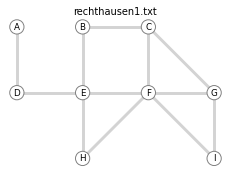

In [ ]:
import matplotlib.pyplot as plt


def zeichne(achse, pos, nachbarn, routen=[], titel='', namen=True):
    """routen: Liste von Paaren (Liste von Kreuzungen, Farbe)"""
    for a in nachbarn:
        for b in nachbarn[a]:
            if a < b:                                        # jede Straße nur einmal zeichnen
                achse.plot([pos[a][0], pos[b][0]], [pos[a][1], pos[b][1]], color='lightgray', linewidth=3, zorder=1)
    for route, farbe in routen:
        for i in range(len(route) - 1):
            achse.annotate('', xy=pos[route[i + 1]], xytext=pos[route[i]], zorder=2,
                           arrowprops=dict(arrowstyle='-|>', color=farbe, linewidth=2, shrinkA=7, shrinkB=7))
    if namen:
        for k in pos:
            achse.text(pos[k][0], pos[k][1], k, ha='center', va='center', fontsize=9, zorder=3,
                       bbox=dict(boxstyle='circle', facecolor='white', edgecolor='gray'))
    achse.set_aspect('equal')
    achse.set_title(titel, fontsize=10)
    achse.axis('off')


fig, achse = plt.subplots(figsize=(4, 3))
zeichne(achse, pos1, nachbarn1, titel='rechthausen1.txt')
plt.show()

## Schritt 2: Wann ist Abbiegen Linksabbiegen? (Teil 1)

Wir setzen die Definition aus der Idee in drei kleine Funktionen um.

- `richtung(pos, von, nach)` ist der Winkel der Strecke wie in Mathe: gegen den Uhrzeigersinn ab der x-Achse.
- `drehwinkel(pos, kreuzung, woher, wohin)`: Man steht in der Kreuzung, schaut zu `woher` und dreht sich **im Uhrzeigersinn** zu `wohin`.
  Weil `richtung` gegen den Uhrzeigersinn zählt, ist das `richtung(..., woher) - richtung(..., wohin)`, gerechnet modulo 360.
  Wir runden auf sechs Stellen nach dem Komma. Sonst käme statt 180 auch einmal 179.99999999999997 heraus, und zwei gleich große
  Differenzwinkel wären nicht mehr gleich.
- `gegenverkehr(pos, nachbarn, kreuzung, woher)` gibt den Drehwinkel des Gegenverkehrs und den Namen seiner Straße zurück; bei einem
  Gleichstand `(180, None)` für den gedachten Gegenverkehr.

Dann ist `erlaubt` nur noch ein Vergleich: Der Drehwinkel der Zielstraße darf nicht kleiner sein als der des Gegenverkehrs.

In [ ]:
def richtung(pos, von, nach):
    """Winkel der Strecke von -> nach in Grad, gegen den Uhrzeigersinn ab der x-Achse."""
    dx = pos[nach][0] - pos[von][0]
    dy = pos[nach][1] - pos[von][1]
    return math.degrees(math.atan2(dy, dx))


def drehwinkel(pos, kreuzung, woher, wohin):
    """In der Kreuzung stehen, zu woher schauen, im Uhrzeigersinn zu wohin drehen: Winkel von 0 bis unter 360."""
    w = richtung(pos, kreuzung, woher) - richtung(pos, kreuzung, wohin)
    return round(w, 6) % 360


def gegenverkehr(pos, nachbarn, kreuzung, woher):
    """(Drehwinkel, Straße) des Gegenverkehrs; bei zwei gleich stark entgegengesetzten Straßen (180, None)."""
    bester = -1
    for c in nachbarn[kreuzung]:
        w = drehwinkel(pos, kreuzung, woher, c)
        differenz = round(min(w, 360 - w), 6)                # der kleinere der beiden Winkel zwischen den Straßen
        if differenz > bester:
            bester = differenz
            ergebnis = (w, c)
        elif differenz == bester:                            # Gleichstand: gedachter Gegenverkehr genau gegenüber
            ergebnis = (180, None)
    return ergebnis


def erlaubt(pos, nachbarn, woher, kreuzung, wohin):
    """Darf man von woher kommend an kreuzung nach wohin fahren?"""
    w_gegen, strasse = gegenverkehr(pos, nachbarn, kreuzung, woher)
    return drehwinkel(pos, kreuzung, woher, wohin) >= w_gegen


def zeige_kreuzung(pos, nachbarn, woher, kreuzung):
    w_gegen, strasse = gegenverkehr(pos, nachbarn, kreuzung, woher)
    if strasse is None:
        strasse = 'gedacht'
    print(f'An {kreuzung}, aus {woher} kommend: Gegenverkehr aus {strasse}, Drehwinkel {w_gegen:g}')
    for c in nachbarn[kreuzung]:
        w = drehwinkel(pos, kreuzung, woher, c)
        if w >= w_gegen:
            urteil = 'erlaubt'
        else:
            urteil = 'verboten'
        print(f'   nach {c}: Drehwinkel {w:3g}, Differenzwinkel {min(w, 360 - w):3g}, {urteil}')


zeige_kreuzung(pos1, nachbarn1, 'D', 'E')
zeige_kreuzung(pos1, nachbarn1, 'I', 'G')

An E, aus D kommend: Gegenverkehr aus F, Drehwinkel 180
   nach B: Drehwinkel  90, Differenzwinkel  90, verboten
   nach D: Drehwinkel   0, Differenzwinkel   0, verboten
   nach F: Drehwinkel 180, Differenzwinkel 180, erlaubt
   nach H: Drehwinkel 270, Differenzwinkel  90, erlaubt
An G, aus I kommend: Gegenverkehr aus C, Drehwinkel 135
   nach C: Drehwinkel 135, Differenzwinkel 135, erlaubt
   nach F: Drehwinkel  90, Differenzwinkel  90, verboten
   nach I: Drehwinkel   0, Differenzwinkel   0, verboten


An E kommt man aus D (von Westen) und fährt nach Osten. Der Gegenverkehr kommt aus F (geradeaus). Vor ihm liegen beim Drehen im
Uhrzeigersinn D selbst (Wenden, 0°) und B (90°, links): verboten. H (270°, rechts) ist erlaubt. An G kommt man aus I von Süden. C (135°)
ist stärker entgegengesetzt als F (90°), der Gegenverkehr kommt also aus C, und F ist verboten. Darum ist IGF keine erlaubte Route.

`route_erlaubt` prüft eine ganze Route, als Text wie in der Aufgabe:

In [ ]:
def route_erlaubt(pos, nachbarn, route):
    for i in range(1, len(route) - 1):
        if not erlaubt(pos, nachbarn, route[i - 1], route[i], route[i + 1]):
            return False
    return True


for route in ['DADEF', 'GCB', 'FEBC', 'DEB', 'IGF']:
    print(route, route_erlaubt(pos1, nachbarn1, route))

DADEF True
GCB True
FEBC True
DEB False
IGF False


Genau wie verlangt: DADEF (Wenden in der Sackgasse A), GCB und FEBC sind erlaubt, DEB und IGF nicht.

Die Lösungshinweise beschreiben dieselbe Regel mit Kompasswinkeln (0° = y-Achse, 90° = x-Achse) und einer Fallunterscheidung: Sind α, β,
γ die Winkel der Herkunftsstraße, des Gegenverkehrs und der Zielstraße, dann ist für β > α genau β > γ ≥ α verboten, für α > β ist genau
α > γ ≥ β erlaubt. Unser Drehwinkel fasst beide Fälle in einem Vergleich zusammen. Zur Probe vergleichen wir beide Fassungen an allen
Kreuzungen von 200 Zufallsstädten (die Funktion `zufallsstadt` kommt erst in Schritt 9, darum steht der Vergleich dort).

## Schritt 3: Beispiele für die Definition (Teil 2)

Acht kleine Kreuzungen: Man kommt immer von unten aus der Straße S (schwarzer Pfeil). Grün sind die erlaubten Straßen, rot die
verbotenen, (G) markiert den Gegenverkehr. Gestrichelt ist der gedachte Gegenverkehr bei einem Gleichstand.

Sackgasse (d = 1)        erlaubt: S
Knick (d = 2)            erlaubt: 1
gewöhnliche Kreuzung     erlaubt: 2 3
T-Kreuzung von unten     erlaubt: 2
Einmündung von links     erlaubt: 2
Gabelung                 erlaubt: 2
zwei Straßen nach links  erlaubt: 1 3
Stern (d = 5)            erlaubt: 2 3 4


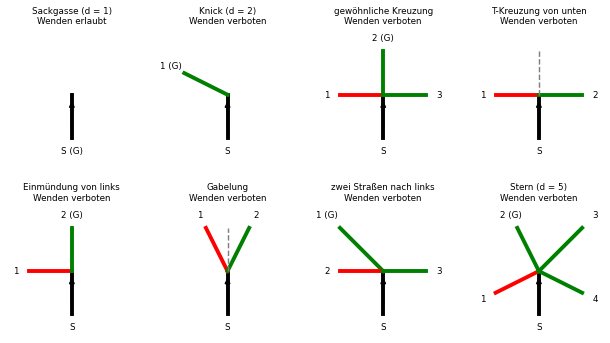

In [ ]:
BEISPIEL_KREUZUNGEN = [
    ('Sackgasse (d = 1)', {'S': (0, -2)}),
    ('Knick (d = 2)', {'S': (0, -2), '1': (-2, 1)}),
    ('gewöhnliche Kreuzung', {'S': (0, -2), '1': (-2, 0), '2': (0, 2), '3': (2, 0)}),
    ('T-Kreuzung von unten', {'S': (0, -2), '1': (-2, 0), '2': (2, 0)}),
    ('Einmündung von links', {'S': (0, -2), '1': (-2, 0), '2': (0, 2)}),
    ('Gabelung', {'S': (0, -2), '1': (-1, 2), '2': (1, 2)}),
    ('zwei Straßen nach links', {'S': (0, -2), '1': (-2, 2), '2': (-2, 0), '3': (2, 0)}),
    ('Stern (d = 5)', {'S': (0, -2), '1': (-2, -1), '2': (-1, 2), '3': (2, 2), '4': (2, -1)}),
]


def kleine_kreuzung(enden):
    """Kreuzung X im Nullpunkt mit Straßen zu den Enden."""
    pos = {'X': (0, 0)}
    nachbarn = {'X': []}
    for name in enden:
        pos[name] = enden[name]
        nachbarn[name] = ['X']
        nachbarn['X'].append(name)
    return pos, nachbarn


def zeige_beispiel(achse, titel, enden):
    pos, nachbarn = kleine_kreuzung(enden)
    w_gegen, strasse = gegenverkehr(pos, nachbarn, 'X', 'S')
    for c in enden:
        if c == 'S':
            farbe = 'black'
        elif erlaubt(pos, nachbarn, 'S', 'X', c):
            farbe = 'green'
        else:
            farbe = 'red'
        achse.plot([0, pos[c][0]], [0, pos[c][1]], color=farbe, linewidth=4)
        beschriftung = c
        if c == strasse:
            beschriftung = c + ' (G)'
        achse.text(1.3 * pos[c][0], 1.3 * pos[c][1], beschriftung, ha='center', va='center', fontsize=9)
    if strasse is None:
        achse.plot([0, 0], [0, 2], color='gray', linestyle='--')
    achse.annotate('', xy=(0, -0.2), xytext=(0, -1.6), arrowprops=dict(arrowstyle='-|>', color='black', linewidth=2))
    if erlaubt(pos, nachbarn, 'S', 'X', 'S'):
        wenden = 'Wenden erlaubt'
    else:
        wenden = 'Wenden verboten'
    achse.set_title(titel + '\n' + wenden, fontsize=9)
    achse.set_xlim(-3, 3)
    achse.set_ylim(-3, 3)
    achse.set_aspect('equal')
    achse.axis('off')


fig, achsen = plt.subplots(2, 4, figsize=(11, 6))
for i in range(len(BEISPIEL_KREUZUNGEN)):
    titel, enden = BEISPIEL_KREUZUNGEN[i]
    zeige_beispiel(achsen[i // 4][i % 4], titel, enden)
plt.show()

for titel, enden in BEISPIEL_KREUZUNGEN:
    pos, nachbarn = kleine_kreuzung(enden)
    frei = [c for c in enden if erlaubt(pos, nachbarn, 'S', 'X', c)]
    print(f'{titel:24} erlaubt: {" ".join(frei)}')

- **Sackgasse:** Wenden ist erlaubt, es gibt keinen Gegenverkehr, mit dem man zusammenstoßen könnte.
- **Knick:** Man folgt der Straße, auch wenn sie nach links abknickt; man bleibt dabei auf der eigenen Spur.
- **Gewöhnliche Kreuzung:** geradeaus (2) und rechts (3), nicht links (1).
- **T-Kreuzung von unten:** Beide Straßen sind gleich stark entgegengesetzt, der gedachte Gegenverkehr kommt von geradeaus. Nur rechts
  (2) ist erlaubt (Abbildung 5 der Lösungshinweise).
- **Einmündung von links:** geradeaus ja, in die Einmündung nein. Eine Einmündung von rechts wäre erlaubt.
- **Gabelung:** Auch hier ein Gleichstand: Nur die rechte Straße ist erlaubt. Darüber kann man streiten (in der Wirklichkeit gibt es
  an einer Gabelung meist keinen Gegenverkehr, der einen stört), aber die Regel entscheidet eindeutig.
- **Zwei Straßen nach links:** Beide Straßen 1 und 2 führen nach links. Straße 1 ist aber die am stärksten entgegengesetzte, aus ihr
  kommt der Gegenverkehr, und in sie darf man fahren, ohne eine Gegenspur zu kreuzen. Nur 2 ist verboten (Abbildung 1 der Hinweise).
- **Stern:** Gegenverkehr aus 2, verboten ist nur 1.

## Schritt 4: Die Tabelle der erlaubten Abbiegevorgänge

Ob ich an einer Kreuzung `b` nach `c` weiterfahren darf, hängt nur davon ab, aus welcher Kreuzung `a` ich gekommen bin. Wir rechnen das
für alle Fahrten einmal aus und speichern es: `weiter[(a, b)]` ist die Liste aller `c`, zu denen man nach der Fahrt von `a` nach `b`
weiterfahren darf. Ein Paar `(a, b)` nennen wir einen **Zustand**: „Ich bin gerade von a nach b gefahren.“ Jeder Straßenabschnitt gibt
zwei Zustände, einen für jede Fahrtrichtung.

Mit `mit_verbot=False` entsteht die Tabelle ohne Verbot (alle Nachbarn), die wir für den Vergleich in Teil 5 brauchen.

Die Lösungshinweise machen dasselbe mit einem „aufgeblähten“ Graphen: Jede Straße bekommt an jeder Kreuzung einen Knoten für die
hineinführende und einen für die hinausführende Spur, und Kanten gibt es nur für erlaubte Abbiegevorgänge. Unsere Zustände entsprechen
den Spuren, die Tabelle den Kanten.

In [ ]:
def abbiege_tabelle(pos, nachbarn, mit_verbot=True):
    weiter = {}
    for b in nachbarn:
        for a in nachbarn[b]:
            weiter[(a, b)] = []
            for c in nachbarn[b]:
                if not mit_verbot or erlaubt(pos, nachbarn, a, b, c):
                    weiter[(a, b)].append(c)
    return weiter


def zaehle_abbiegen(weiter):
    summe = 0
    for zustand in weiter:
        summe = summe + len(weiter[zustand])
    return summe


weiter1 = abbiege_tabelle(pos1, nachbarn1)
ohne1 = abbiege_tabelle(pos1, nachbarn1, mit_verbot=False)
print(len(weiter1), 'Zustände,', zaehle_abbiegen(weiter1), 'von', zaehle_abbiegen(ohne1), 'Abbiegevorgängen erlaubt')
for a in nachbarn1['E']:
    print(f'aus {a} nach E, dann weiter nach:', ' '.join(weiter1[(a, 'E')]))

24 Zustände, 37 von 76 Abbiegevorgängen erlaubt
aus B nach E, dann weiter nach: D H
aus D nach E, dann weiter nach: F H
aus F nach E, dann weiter nach: B D
aus H nach E, dann weiter nach: B F


An der Kreuzung E mit vier Straßen darf man von jeder Straße aus nur noch in zwei weiterfahren (geradeaus und rechts, auch wenn das
Netz nicht überall rechte Winkel hat). Insgesamt sind von 76 Abbiegevorgängen (das Wenden mitgezählt) noch 37 erlaubt, also knapp die
Hälfte.

## Schritt 5: Wenigste Straßenabschnitte mit der Breitensuche (Teil 3)

Die Breitensuche läuft über die Zustände. Am Start darf man in jede Richtung losfahren: Alle Zustände `(start, x)` haben den Abstand 1.
Von einem Zustand `(a, b)` kommt man zu allen `(b, c)` mit `c` in `weiter[(a, b)]`. `vorher` merkt sich für jeden Zustand, woher wir ihn
erreicht haben, damit wir die Route am Ende rückwärts ablesen können.

An einer Kreuzung `t` kann man in mehreren Zuständen ankommen (aus verschiedenen Straßen). `ankunft` sucht für jede Kreuzung den
Zustand mit dem kleinsten Abstand heraus.

In [ ]:
from collections import deque


def breitensuche(nachbarn, weiter, start):
    abstand = {}
    vorher = {}
    schlange = deque()
    for x in nachbarn[start]:                                # am Start in jede Richtung
        abstand[(start, x)] = 1
        vorher[(start, x)] = None
        schlange.append((start, x))
    while len(schlange) > 0:
        a, b = schlange.popleft()
        for c in weiter[(a, b)]:
            if (b, c) not in abstand:
                abstand[(b, c)] = abstand[(a, b)] + 1
                vorher[(b, c)] = (a, b)
                schlange.append((b, c))
    return abstand, vorher


def ankunft(abstand, start):
    """bestes[t] = Zustand (a, t) mit dem kleinsten Abstand, für jede erreichte Kreuzung t außer start."""
    bestes = {}
    for zustand in abstand:
        t = zustand[1]
        if t != start and (t not in bestes or abstand[zustand] < abstand[bestes[t]]):
            bestes[t] = zustand
    return bestes


def route_bis(vorher, zustand):
    """Die Kreuzungen vom Start bis zum Zustand, rückwärts über vorher abgelesen."""
    route = [zustand[1]]
    while zustand is not None:
        route.append(zustand[0])
        zustand = vorher[zustand]
    route.reverse()
    return route


for start, ziel in [('A', 'C'), ('H', 'A')]:
    abstand, vorher = breitensuche(nachbarn1, weiter1, start)
    zustand = ankunft(abstand, start)[ziel]
    print(f'{start} nach {ziel}: {abstand[zustand]} Straßenabschnitte, Route', '-'.join(route_bis(vorher, zustand)))

A nach C: 6 Straßenabschnitte, Route A-D-E-F-I-G-C
H nach A: 7 Straßenabschnitte, Route H-E-B-C-F-E-D-A


Bevor wir den Routen glauben, prüft sie ein **Schiedsrichter**: Start und Ziel stimmen, je zwei aufeinanderfolgende Kreuzungen sind durch
eine Straße verbunden, und an keiner Kreuzung wird links abgebogen oder verboten gewendet.

In [ ]:
def pruefe_route(pos, nachbarn, route, start, ziel):
    if route[0] != start or route[-1] != ziel:
        return 'Start oder Ziel falsch'
    for i in range(len(route) - 1):
        if route[i + 1] not in nachbarn[route[i]]:
            return f'keine Straße von {route[i]} nach {route[i + 1]}'
    for i in range(1, len(route) - 1):
        if not erlaubt(pos, nachbarn, route[i - 1], route[i], route[i + 1]):
            return f'verbotenes Abbiegen bei {route[i]}'
    return 'ok'


print(pruefe_route(pos1, nachbarn1, list('ADEFIGC'), 'A', 'C'), pruefe_route(pos1, nachbarn1, list('ADEBC'), 'A', 'C'))

ok verbotenes Abbiegen bei E


A-D-E-F-I-G-C ist in Ordnung, die kurze Route A-D-E-B-C dagegen nicht: Bei E müsste man von D kommend nach B links abbiegen.

## Schritt 6: Kürzeste Gesamtlänge mit Dijkstra

Sind die Straßen verschieden lang, reicht die Breitensuche nicht mehr. Der **Algorithmus von Dijkstra** nimmt immer den Zustand mit dem
kleinsten bisher bekannten Abstand aus einer Prioritätswarteschlange und ist dann sicher, dass dieser Abstand der kürzeste ist. Ein
Eintrag in der Warteschlange ist ein Tupel `(abstand, a, b)`. Ein Zustand kann mehrmals in der Warteschlange stehen, wenn wir später
einen kürzeren Weg zu ihm finden; die älteren Einträge überspringen wir mit der Menge `fertig`.

Mit `mass='anzahl'` zählt jede Straße 1, mit `mass='laenge'` ihre Länge. So rechnet dieselbe Funktion beide Weglängenmaße.

In [ ]:
import heapq


def strecke(pos, a, b, mass):
    if mass == 'anzahl':
        return 1
    return math.hypot(pos[b][0] - pos[a][0], pos[b][1] - pos[a][1])


def dijkstra(pos, nachbarn, weiter, start, mass):
    abstand = {}
    vorher = {}
    fertig = set()
    warteschlange = []
    for x in nachbarn[start]:
        abstand[(start, x)] = strecke(pos, start, x, mass)
        vorher[(start, x)] = None
        heapq.heappush(warteschlange, (abstand[(start, x)], start, x))
    while len(warteschlange) > 0:
        d, a, b = heapq.heappop(warteschlange)               # der Zustand mit dem kleinsten Abstand
        if (a, b) in fertig:
            continue
        fertig.add((a, b))
        for c in weiter[(a, b)]:
            neu = d + strecke(pos, b, c, mass)
            if (b, c) not in abstand or neu < abstand[(b, c)]:
                abstand[(b, c)] = neu
                vorher[(b, c)] = (a, b)
                heapq.heappush(warteschlange, (neu, b, c))
    return abstand, vorher


def kuerzeste_route(pos, nachbarn, weiter, start, ziel, mass):
    """(Weglänge, Route) oder None, wenn das Ziel nicht erreichbar ist."""
    abstand, vorher = dijkstra(pos, nachbarn, weiter, start, mass)
    bestes = ankunft(abstand, start)
    if ziel not in bestes:
        return None
    return abstand[bestes[ziel]], route_bis(vorher, bestes[ziel])


for mass in ['anzahl', 'laenge']:
    for start, ziel in [('A', 'C'), ('H', 'A')]:
        l_mit, route_mit = kuerzeste_route(pos1, nachbarn1, weiter1, start, ziel, mass)
        l_ohne, route_ohne = kuerzeste_route(pos1, nachbarn1, ohne1, start, ziel, mass)
        print(f'{mass:7} {start} nach {ziel}: {l_mit:6.3f} {"-".join(route_mit):16}',
              f'ohne Verbot {l_ohne:6.3f} {"-".join(route_ohne):10}',
              pruefe_route(pos1, nachbarn1, route_mit, start, ziel))

anzahl  A nach C:  6.000 A-D-E-F-I-G-C    ohne Verbot  4.000 A-D-E-B-C  ok
anzahl  H nach A:  7.000 H-E-B-C-F-E-D-A  ohne Verbot  3.000 H-E-D-A    ok
laenge  A nach C: 13.657 A-D-E-F-I-G-C    ohne Verbot  8.000 A-D-E-B-C  ok
laenge  H nach A: 14.000 H-E-B-C-F-E-D-A  ohne Verbot  6.000 H-E-D-A    ok


Die Antworten auf die Fragen aus Teil 3, genau wie in den Lösungshinweisen:

- **Von A nach C:** A-D-E-F-I-G-C mit 6 Straßenabschnitten und der Länge 8 + 4√2 ≈ 13,657 statt A-D-E-B-C (4 Abschnitte, Länge 8).
- **Von H nach A:** H-E-B-C-F-E-D-A mit 7 Abschnitten und der Länge 14 statt H-E-D-A (3 Abschnitte, Länge 6). Hier fährt man eine
  Schleife um das Quadrat B-C-F-E, um an E aus der richtigen Richtung anzukommen.

Bei beiden Maßen ist hier dieselbe Route die kürzeste; die Breitensuche aus Schritt 5 liefert dieselben Anzahlen.

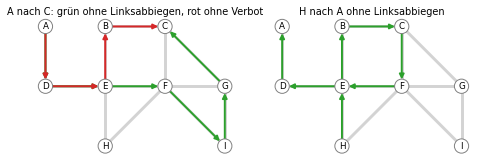

In [ ]:
fig, achsen = plt.subplots(1, 2, figsize=(8, 3))
zeichne(achsen[0], pos1, nachbarn1, [(list('ADEFIGC'), 'tab:green'), (list('ADEBC'), 'tab:red')],
        'A nach C: grün ohne Linksabbiegen, rot ohne Verbot')
zeichne(achsen[1], pos1, nachbarn1, [(list('HEBCFEDA'), 'tab:green')], 'H nach A ohne Linksabbiegen')
plt.show()

## Schritt 7: Ist jede Kreuzung von jeder aus erreichbar? (Teil 4)

Wir starten von jeder Kreuzung eine Breitensuche und sammeln die Paare (Start, Ziel), bei denen das Ziel nie erreicht wird. Ein Ziel,
das gleich dem Start ist, lassen wir weg: Dort ist man schon.

In [ ]:
def nicht_erreichbar(pos, nachbarn, weiter):
    paare = []
    for s in sorted(pos):
        abstand, vorher = breitensuche(nachbarn, weiter, s)
        erreicht = ankunft(abstand, s)
        for t in sorted(pos):
            if t != s and t not in erreicht:
                paare.append((s, t))
    return paare


print('rechthausen1.txt, nicht erreichbar:', nicht_erreichbar(pos1, nachbarn1, weiter1))

rechthausen1.txt, nicht erreichbar: []


Im Netz der Aufgabe ist alles von überall erreichbar, wie in den Lösungshinweisen.

Die Hinweise gehen weiter. Sie behaupten: Ist ein Netz zusammenhängend und darf man in Sackgassen wenden, dann bleibt **jede** Kreuzung
von jeder aus erreichbar. Die Begründung: Darf man nicht in eine Straße abbiegen, fährt man in die Straße des Gegenverkehrs, kommt
irgendwann „aus der anderen Richtung“ zur Kreuzung zurück und darf dann rechts in die gewünschte Straße einbiegen.

Unser Programm findet aber ein Gegenbeispiel, eine **Ringstraße** mit zwei Sackgassen: Von E führt eine nach außen (nach G), von B eine
nach innen (nach H).

ringstrasse.txt, nicht erreichbar: [('G', 'H'), ('H', 'G')]
GEFABCDEG True
HBAFEDCBH True
GEFABH False
HBAFEG False


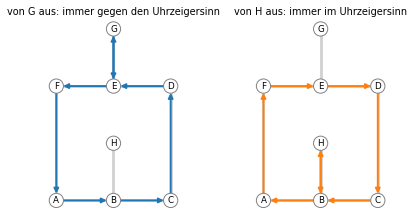

In [ ]:
pos_ring, nachbarn_ring = lies_datei('eigene_testdaten/ringstrasse.txt')
weiter_ring = abbiege_tabelle(pos_ring, nachbarn_ring)
print('ringstrasse.txt, nicht erreichbar:', nicht_erreichbar(pos_ring, nachbarn_ring, weiter_ring))

fig, achsen = plt.subplots(1, 2, figsize=(7, 3.5))
zeichne(achsen[0], pos_ring, nachbarn_ring, [(list('GEFABCDEG'), 'tab:blue')], 'von G aus: immer gegen den Uhrzeigersinn')
zeichne(achsen[1], pos_ring, nachbarn_ring, [(list('HBAFEDCBH'), 'tab:orange')], 'von H aus: immer im Uhrzeigersinn')
plt.show()
for route in ['GEFABCDEG', 'HBAFEDCBH', 'GEFABH', 'HBAFEG']:
    print(route, route_erlaubt(pos_ring, nachbarn_ring, route))

Von G kommt man nicht nach H und von H nicht nach G. Das kann man auch von Hand nachvollziehen:

- Wer aus der Sackgasse G zurück nach E fährt, kommt an eine T-Kreuzung von unten und darf nur rechts abbiegen, also nach F. Damit fährt
  er **gegen den Uhrzeigersinn** um den Ring. An den Ecken A, C, D, F (d = 2) kann er nicht wenden.
- Bei B möchte er nach H, nach innen. Gegen den Uhrzeigersinn liegt das Innere des Rings aber **links**: verboten. In die Sackgasse G
  darf er bei E wieder (sie liegt rechts), aber wenn er zurückkommt, muss er wieder rechts abbiegen und fährt wieder gegen den
  Uhrzeigersinn. Er kommt nie aus dieser Richtung heraus.
- Wer von H kommt, fährt genauso immer im Uhrzeigersinn, und dann liegt G links.

Wo steckt der Fehler in der Begründung der Hinweise? Man kommt zwar zur Kreuzung zurück, aber **nicht unbedingt aus der Straße des
Gegenverkehrs**. Wer bei B nach H möchte und deshalb geradeaus nach C weiterfährt, kommt nach der Runde wieder aus A bei B an, nicht aus
C. Von dort ist H wieder links.

Für Teil 4 heißt das: Man muss wirklich nachrechnen, die Antwort ist nicht immer „ja“. In den Beispielen der Community, die die
Lösungshinweise nennen, war laut den Hinweisen alles erreichbar. In Schritt 9 sehen wir, dass es in zufälligen Städten durchaus vorkommt,
dass etwas unerreichbar ist.

## Schritt 8: Wo verlängert das Verbot den Weg am meisten? (Teil 5)

Für jede Startkreuzung rechnen wir Dijkstra zweimal, mit und ohne Verbot, und teilen für jede Zielkreuzung die beiden Weglängen. Die
Liste `rangliste` enthält Tupel `(-faktor, start, ziel, länge mit, länge ohne)`. Das Minuszeichen sorgt dafür, dass `sorted` die
größten Faktoren nach vorn bringt und bei Gleichstand nach Start und Ziel alphabetisch ordnet. Wir runden den Faktor auf neun Stellen,
damit gleiche Faktoren auch als gleich erkannt werden. Paare, die mit Verbot nicht erreichbar sind, haben keinen Faktor (sie hat schon
Teil 4 gefunden).

In [ ]:
def rangliste(pos, nachbarn, mass):
    mit = abbiege_tabelle(pos, nachbarn)
    ohne = abbiege_tabelle(pos, nachbarn, mit_verbot=False)
    liste = []
    for s in sorted(pos):
        abstand_mit, vorher = dijkstra(pos, nachbarn, mit, s, mass)
        abstand_ohne, vorher = dijkstra(pos, nachbarn, ohne, s, mass)
        an_mit = ankunft(abstand_mit, s)
        an_ohne = ankunft(abstand_ohne, s)
        for t in sorted(an_mit):
            l_mit = abstand_mit[an_mit[t]]
            l_ohne = abstand_ohne[an_ohne[t]]
            liste.append((-round(l_mit / l_ohne, 9), s, t, l_mit, l_ohne))
    return sorted(liste)


for mass in ['anzahl', 'laenge']:
    print('Maß:', mass)
    for minus_faktor, s, t, l_mit, l_ohne in rangliste(pos1, nachbarn1, mass)[:4]:
        print(f'   {s} nach {t}: Faktor {-minus_faktor:.4f} ({l_mit:.3f} statt {l_ohne:.3f})')

Maß: anzahl
   H nach D: Faktor 3.0000 (6.000 statt 2.000)
   D nach B: Faktor 2.5000 (5.000 statt 2.000)
   I nach H: Faktor 2.5000 (5.000 statt 2.000)
   H nach A: Faktor 2.3333 (7.000 statt 3.000)
Maß: laenge
   H nach D: Faktor 3.0000 (12.000 statt 4.000)
   D nach B: Faktor 2.7071 (10.828 statt 4.000)
   H nach A: Faktor 2.3333 (14.000 statt 6.000)
   A nach B: Faktor 2.1381 (12.828 statt 6.000)


Bei beiden Maßen ist das Paar **H nach D** am stärksten betroffen, mit dem Faktor 3: ohne Verbot H-E-D (2 Abschnitte, Länge 4), mit
Verbot dieselbe Schleife wie oben, H-E-B-C-F-E-D (6 Abschnitte, Länge 12). Das ist genau das Ergebnis der Lösungshinweise. Auf den
Plätzen dahinter unterscheiden sich die Maße: Bei der Anzahl folgen D nach B und I nach H mit 2,5, bei der Länge D nach B mit 2,707.

In [ ]:
for mass in ['anzahl', 'laenge']:
    print(mass, kuerzeste_route(pos1, nachbarn1, weiter1, 'H', 'D', mass), kuerzeste_route(pos1, nachbarn1, ohne1, 'H', 'D', mass))

anzahl (6, ['H', 'E', 'B', 'C', 'F', 'E', 'D']) (2, ['H', 'E', 'D'])
laenge (12.0, ['H', 'E', 'B', 'C', 'F', 'E', 'D']) (4.0, ['H', 'E', 'D'])


## Schritt 9: Alle Beispiele (Teil 6)

`bericht` fasst alles zusammen: Größe des Netzes, Anteil der erlaubten Abbiegevorgänge, nicht erreichbare Paare und das am stärksten
betroffene Paar für beide Maße samt Routen (lange Routen gekürzt).

In [ ]:
def kurz(route):
    if len(route) <= 14:
        return '-'.join(route)
    return '-'.join(route[:6]) + f' ... ({len(route) - 9} weitere) ... ' + '-'.join(route[-3:])


def zahl(x, mass):
    if mass == 'anzahl':
        return str(x)
    return f'{x:.2f}'


def bericht(name, pos, nachbarn):
    mit = abbiege_tabelle(pos, nachbarn)
    ohne = abbiege_tabelle(pos, nachbarn, mit_verbot=False)
    paare = nicht_erreichbar(pos, nachbarn, mit)
    print(f'{name}: {len(pos)} Kreuzungen, {anzahl_strassen(nachbarn)} Straßenabschnitte,',
          f'{zaehle_abbiegen(mit)} von {zaehle_abbiegen(ohne)} Abbiegevorgängen erlaubt')
    if len(paare) == 0:
        print('   Jede Kreuzung ist von jeder aus erreichbar.')
    else:
        print(f'   {len(paare)} Paare nicht erreichbar, zum Beispiel', paare[:4])
    ergebnis = {}
    for mass in ['anzahl', 'laenge']:
        minus_faktor, s, t, l_mit, l_ohne = rangliste(pos, nachbarn, mass)[0]
        l1, route_mit = kuerzeste_route(pos, nachbarn, mit, s, t, mass)
        l2, route_ohne = kuerzeste_route(pos, nachbarn, ohne, s, t, mass)
        print(f'   {mass}: größter Faktor {-minus_faktor:.4f} von {s} nach {t}')
        print(f'      ohne Verbot {zahl(l_ohne, mass):>6}: {kurz(route_ohne)}')
        print(f'      mit Verbot  {zahl(l_mit, mass):>6}: {kurz(route_mit)}',
              f'(Schiedsrichter: {pruefe_route(pos, nachbarn, route_mit, s, t)})')
        ergebnis[mass] = (-minus_faktor, s, t, route_mit)
    return paare, ergebnis


ergebnisse = {}
ergebnisse['rechthausen1'] = bericht('rechthausen1.txt', pos1, nachbarn1)
pos_sack, nachbarn_sack = lies_datei('eigene_testdaten/sackgassen.txt')
ergebnisse['sackgassen'] = bericht('sackgassen.txt', pos_sack, nachbarn_sack)
ergebnisse['ringstrasse'] = bericht('ringstrasse.txt', pos_ring, nachbarn_ring)

rechthausen1.txt: 9 Kreuzungen, 12 Straßenabschnitte, 37 von 76 Abbiegevorgängen erlaubt
   Jede Kreuzung ist von jeder aus erreichbar.
   anzahl: größter Faktor 3.0000 von H nach D
      ohne Verbot      2: H-E-D
      mit Verbot       6: H-E-B-C-F-E-D (Schiedsrichter: ok)
   laenge: größter Faktor 3.0000 von H nach D
      ohne Verbot   4.00: H-E-D
      mit Verbot   12.00: H-E-B-C-F-E-D (Schiedsrichter: ok)
sackgassen.txt: 5 Kreuzungen, 4 Straßenabschnitte, 9 von 16 Abbiegevorgängen erlaubt
   Jede Kreuzung ist von jeder aus erreichbar.
   anzahl: größter Faktor 3.0000 von E nach C
      ohne Verbot      2: E-D-C
      mit Verbot       6: E-D-B-A-B-D-C (Schiedsrichter: ok)
   laenge: größter Faktor 3.0000 von E nach C
      ohne Verbot   2.00: E-D-C
      mit Verbot    6.00: E-D-B-A-B-D-C (Schiedsrichter: ok)
ringstrasse.txt: 8 Kreuzungen, 8 Straßenabschnitte, 18 von 36 Abbiegevorgängen erlaubt
   2 Paare nicht erreichbar, zum Beispiel [('G', 'H'), ('H', 'G')]
   anzahl: größter Fak

`sackgassen.txt` haben wir nach der Beschreibung des Beispiels von Leon Windheuser in den Lösungshinweisen nachgebaut (5 Kreuzungen,
4 Straßen, die Koordinaten sind von uns). Die Hinweise nennen dafür E nach C mit dem Faktor 3, ohne Verbot E-D-C (Länge 2), mit Verbot
E-D-B-A-B-D-C (Länge 6), und genau das finden wir auch: Man fährt in die Sackgasse A, wendet dort und kommt so aus der richtigen Richtung
nach D. Bei der Ringstraße fehlen die beiden Paare G nach H und H nach G; unter den übrigen ist der größte Faktor 3 (Anzahl) bzw.
4 (Länge).

Jetzt größere Netze. `zufallsstadt` legt die Kreuzungen auf ein Gitter mit 10 m Abstand, verschiebt jede zufällig um bis zu 3 m in x-
und y-Richtung und verbindet Nachbarn im Gitter. Dann streicht sie in zufälliger Reihenfolge Straßen, aber nur, wenn das Netz
zusammenhängend bleibt (Probe mit einer Tiefensuche), bis der gewünschte Anteil fehlt. So entstehen schiefe Kreuzungen, T-Kreuzungen und
Sackgassen. Mit `wackeln=0` und `anteil=0` erhält man ein vollständiges, gerades Gitter.

In [ ]:
import random


def zusammenhaengend(pos, strassen):
    nachbarn = {}
    for k in pos:
        nachbarn[k] = []
    for a, b in strassen:
        nachbarn[a].append(b)
        nachbarn[b].append(a)
    erster = sorted(pos)[0]
    besucht = {erster}
    stapel = [erster]
    while len(stapel) > 0:
        k = stapel.pop()
        for x in nachbarn[k]:
            if x not in besucht:
                besucht.add(x)
                stapel.append(x)
    return len(besucht) == len(pos)


def zufallsstadt(breite, hoehe, anteil, seed, wackeln=3):
    zufall = random.Random(seed)
    pos = {}
    for i in range(breite):
        for j in range(hoehe):
            pos[f'K{i}_{j}'] = (10 * i + zufall.randint(-wackeln, wackeln), 10 * j + zufall.randint(-wackeln, wackeln))
    strassen = []
    for i in range(breite):
        for j in range(hoehe):
            if i + 1 < breite:
                strassen.append((f'K{i}_{j}', f'K{i + 1}_{j}'))
            if j + 1 < hoehe:
                strassen.append((f'K{i}_{j}', f'K{i}_{j + 1}'))
    zufall.shuffle(strassen)
    streichen = int(anteil * len(strassen))                  # so viele Straßen sollen wegfallen
    behalten = list(strassen)
    for strasse in strassen:
        if streichen == 0:
            break
        probe = [x for x in behalten if x != strasse]
        if zusammenhaengend(pos, probe):
            behalten = probe
            streichen = streichen - 1
    nachbarn = {}
    for k in pos:
        nachbarn[k] = []
    for a, b in behalten:
        nachbarn[a].append(b)
        nachbarn[b].append(a)
    return pos, nachbarn


pos_gitter, nachbarn_gitter = zufallsstadt(5, 5, 0, 0, wackeln=0)
ergebnisse['gitter'] = bericht('Gitter 5 x 5', pos_gitter, nachbarn_gitter)

Gitter 5 x 5: 25 Kreuzungen, 40 Straßenabschnitte, 128 von 268 Abbiegevorgängen erlaubt
   Jede Kreuzung ist von jeder aus erreichbar.
   anzahl: größter Faktor 1.0000 von K0_0 nach K0_1
      ohne Verbot      1: K0_0-K0_1
      mit Verbot       1: K0_0-K0_1 (Schiedsrichter: ok)
   laenge: größter Faktor 1.0000 von K0_0 nach K0_1
      ohne Verbot  10.00: K0_0-K0_1
      mit Verbot   10.00: K0_0-K0_1 (Schiedsrichter: ok)


Im vollständigen Gitter verlängert das Verbot **keinen** einzigen Weg (Faktor 1). Der Grund: Am Start darf man in jede Richtung
losfahren. Liegt das Ziel zum Beispiel rechts oben, fährt man erst nach oben und biegt dann rechts ab; liegt es links oben, fährt man
erst nach links und biegt dann rechts (nach oben) ab. Ein kürzester Weg mit nur einer Rechtskurve gibt es also immer.

Die Zufallsstädte sind ganz anders:

In [ ]:
pos_s10, nachbarn_s10 = zufallsstadt(10, 10, 0.25, 2)
ergebnisse['stadt10'] = bericht('Zufallsstadt 10 x 10', pos_s10, nachbarn_s10)

Zufallsstadt 10 x 10: 100 Kreuzungen, 135 Straßenabschnitte, 408 von 810 Abbiegevorgängen erlaubt
   91 Paare nicht erreichbar, zum Beispiel [('K1_1', 'K0_3'), ('K1_1', 'K0_4'), ('K1_1', 'K0_5'), ('K1_1', 'K0_6')]
   anzahl: größter Faktor 8.0000 von K7_0 nach K6_1
      ohne Verbot      2: K7_0-K7_1-K6_1
      mit Verbot      16: K7_0-K7_1-K7_2-K7_3-K6_3-K5_3 ... (8 weitere) ... K7_2-K7_1-K6_1 (Schiedsrichter: ok)
   laenge: größter Faktor 9.7535 von K8_8 nach K9_7
      ohne Verbot  17.44: K8_8-K8_7-K9_7
      mit Verbot  170.10: K8_8-K7_8-K6_8-K6_9-K7_9-K7_8 ... (8 weitere) ... K8_6-K8_7-K9_7 (Schiedsrichter: ok)


Zufallsstadt 15 x 15: 225 Kreuzungen, 315 Straßenabschnitte, 988 von 1948 Abbiegevorgängen erlaubt
   Jede Kreuzung ist von jeder aus erreichbar.
   anzahl: größter Faktor 13.0000 von K3_13 nach K4_14
      ohne Verbot      2: K3_13-K4_13-K4_14
      mit Verbot      26: K3_13-K3_12-K3_11-K2_11-K1_11-K1_12 ... (18 weitere) ... K4_12-K4_13-K4_14 (Schiedsrichter: ok)
   laenge: größter Faktor 12.8809 von K3_13 nach K4_14
      ohne Verbot  19.90: K3_13-K4_13-K4_14
      mit Verbot  256.31: K3_13-K3_12-K3_11-K2_11-K1_11-K1_12 ... (18 weitere) ... K4_12-K4_13-K4_14 (Schiedsrichter: ok)


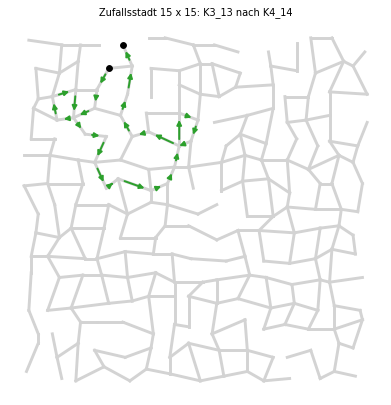

In [ ]:
pos_s15, nachbarn_s15 = zufallsstadt(15, 15, 0.25, 1)
ergebnisse['stadt15'] = bericht('Zufallsstadt 15 x 15', pos_s15, nachbarn_s15)

fig, achse = plt.subplots(figsize=(7, 7))
faktor15, s15, t15, route15 = ergebnisse['stadt15'][1]['laenge']
zeichne(achse, pos_s15, nachbarn_s15, [(route15, 'tab:green')], f'Zufallsstadt 15 x 15: {s15} nach {t15}', namen=False)
achse.plot([pos_s15[s15][0], pos_s15[t15][0]], [pos_s15[s15][1], pos_s15[t15][1]], 'ko', markersize=6)
plt.show()

Die Ergebnisse auf einen Blick (Faktor und Paar):

| Beispiel | Kreuzungen | Straßen | nicht erreichbare Paare | Faktor Anzahl | Faktor Länge |
|---|---|---|---|---|---|
| `rechthausen1.txt` | 9 | 12 | 0 | 3,00 (H nach D) | 3,00 (H nach D) |
| `sackgassen.txt` | 5 | 4 | 0 | 3,00 (E nach C) | 3,00 (E nach C) |
| `ringstrasse.txt` | 8 | 8 | 2 | 3,00 (A nach H) | 4,00 (A nach H) |
| Gitter 5 x 5 | 25 | 40 | 0 | 1,00 (K0_0 nach K0_1) | 1,00 (K0_0 nach K0_1) |
| Zufallsstadt 10 x 10 | 100 | 135 | 91 | 8,00 (K7_0 nach K6_1) | 9,75 (K8_8 nach K9_7) |
| Zufallsstadt 15 x 15 | 225 | 315 | 0 | 13,00 (K3_13 nach K4_14) | 12,88 (K3_13 nach K4_14) |

- In der Zufallsstadt 10 x 10 sind 91 Paare nicht erreichbar. Nicht nur in einem ausgedachten Netz wie der Ringstraße, auch in einer
  zufälligen Stadt kann das Verbot also Verbindungen unmöglich machen.
- Die größten Faktoren gehören zu Kreuzungen, die ohne Verbot nur zwei Straßenabschnitte auseinander liegen. Mit Verbot muss man weit
  ausholen, um aus der richtigen Richtung anzukommen. Der Faktor 13 in der 15 x 15-Stadt heißt: 26 statt 2 Straßenabschnitte.
- Die Lösungshinweise nennen für die Netze von Fabian Michel (26, 72 und 200 Kreuzungen) Faktoren von 6,6 bis 9,4 bei der Länge. Diese
  Netze liegen uns nicht vor; unsere Zufallsstädte sind ähnlich groß, aber sicher anders gebaut, deshalb sind die Zahlen
  nicht direkt vergleichbar.

## Für Neugierige

### Probe: unsere Regel und die Fallunterscheidung der Hinweise

In Schritt 2 haben wir versprochen, unsere Regel mit der Fallunterscheidung der Lösungshinweise zu vergleichen. `erlaubt_hinweise`
rechnet mit Kompasswinkeln (0° = y-Achse, 90° = x-Achse, im Uhrzeigersinn), genau wie dort beschrieben.

In [ ]:
def kompass(pos, kreuzung, ziel):
    return round(90 - richtung(pos, kreuzung, ziel), 6) % 360


def erlaubt_hinweise(pos, nachbarn, woher, kreuzung, wohin):
    alpha = kompass(pos, kreuzung, woher)
    bester = -1
    for c in nachbarn[kreuzung]:
        winkel = kompass(pos, kreuzung, c)
        differenz = round(min(abs(winkel - alpha), 360 - abs(winkel - alpha)), 6)
        if differenz > bester:
            bester = differenz
            beta = winkel
        elif differenz == bester:
            beta = (alpha + 180) % 360                       # gedachter Gegenverkehr
    gamma = kompass(pos, kreuzung, wohin)
    if beta > alpha:
        return not (beta > gamma >= alpha)
    if alpha > beta:
        return alpha > gamma >= beta
    return True                                              # alpha = beta: Sackgasse


verglichen = 0
for seed in range(200):
    pos, nachbarn = zufallsstadt(5, 5, 0.3, seed)
    for b in nachbarn:
        for a in nachbarn[b]:
            for c in nachbarn[b]:
                assert erlaubt(pos, nachbarn, a, b, c) == erlaubt_hinweise(pos, nachbarn, a, b, c)
                verglichen = verglichen + 1
print(verglichen, 'Abbiegevorgänge verglichen, alle gleich entschieden')

28812 Abbiegevorgänge verglichen, alle gleich entschieden


### Wie oft ist etwas unerreichbar?

Wir erzeugen viele kleine Zufallsstädte und zählen, in wie vielen nicht jede Kreuzung von jeder aus erreichbar ist.

In [ ]:
haeufigkeit = []
for breite, hoehe in [(4, 4), (5, 5), (6, 6)]:
    for anteil in [0.15, 0.3]:
        schlecht = 0
        for seed in range(100):
            pos, nachbarn = zufallsstadt(breite, hoehe, anteil, seed)
            if len(nicht_erreichbar(pos, nachbarn, abbiege_tabelle(pos, nachbarn))) > 0:
                schlecht = schlecht + 1
        haeufigkeit.append(schlecht)
        print(f'{breite} x {hoehe}, {anteil:.0%} der Straßen gestrichen: in {schlecht:2} von 100 Städten ist etwas unerreichbar')

4 x 4, 15% der Straßen gestrichen: in  1 von 100 Städten ist etwas unerreichbar
4 x 4, 30% der Straßen gestrichen: in  0 von 100 Städten ist etwas unerreichbar
5 x 5, 15% der Straßen gestrichen: in  0 von 100 Städten ist etwas unerreichbar
5 x 5, 30% der Straßen gestrichen: in  2 von 100 Städten ist etwas unerreichbar
6 x 6, 15% der Straßen gestrichen: in  0 von 100 Städten ist etwas unerreichbar
6 x 6, 30% der Straßen gestrichen: in  1 von 100 Städten ist etwas unerreichbar


Selten (in 4 von 600 Städten), aber es kommt vor; die Zufallsstadt 10 x 10 aus Schritt 9 ist so ein Fall. Ein Navigationssystem für Rechthausen sollte also melden können: „Ohne Linksabbiegen kommst du da nicht hin.“

### Weitere Ideen

- **A\*** statt Dijkstra: Die Luftlinie zum Ziel ist eine Schätzung, die nie zu groß ist. Wer die Zustände nach Abstand plus Luftlinie
  ordnet, findet das Ziel meist schneller (für die Länge; für die Anzahl kann man die Luftlinie durch die längste Straße teilen).
- **Alle Paare auf einmal:** Der Algorithmus von **Floyd und Warshall** rechnet die kürzesten Wege zwischen allen Zuständen in einem
  Durchgang (dynamische Programmierung). Für Teil 4 reicht sogar weniger: Man könnte die **starken Zusammenhangskomponenten** des
  Zustandsgraphen bestimmen (Algorithmus von Tarjan) statt von jeder Kreuzung aus zu suchen.
- **Weitergehende Fragen** aus den Bewertungskriterien: An welcher Stelle würde eine zusätzliche Straße die größte Verlängerung beheben?
  Wie ändert sich der Verkehr auf den einzelnen Straßen? Und Einbahnstraßen: Man nimmt sie einfach nur in einer Richtung in
  `nachbarn` auf.

## Zum Schluss: Rechtsrum mit MiniZinc

Einen kürzesten Weg kann man auch mit MiniZinc suchen. Wege beschreibt man dort als **Fluss**: Für jede Fahrt `e` (unsere Zustände aus
Schritt 4, jede Straße in beide Richtungen) gibt es eine Variable `x[e]` (1 = die Route benutzt sie), für jeden **erlaubten**
Abbiegevorgang `p` aus der Tabelle `weiter` eine Variable `y[p]`. Verbotene Abbiegevorgänge kommen im Modell gar nicht vor, so steckt
das Verbot schon in den Daten.

- In eine benutzte Fahrt kommt man auf genau eine Art hinein: Entweder beginnt die Route mit ihr (`los[e] = 1`, nur möglich, wenn sie am
  Start beginnt), oder genau ein erlaubter Abbiegevorgang führt in sie hinein.
- Aus einer benutzten Fahrt geht es auf genau eine Art weiter: Entweder endet die Route mit ihr (`stopp[e] = 1`, nur am Ziel), oder genau
  ein Abbiegevorgang führt aus ihr hinaus.
- Für unbenutzte Fahrten ist alles 0. Die Route beginnt genau einmal und endet genau einmal.

Minimiert wird die Summe der Längen der benutzten Fahrten. Kreise, die nicht mit der Route zusammenhängen, würden die Bedingungen auch
erfüllen, machen die Summe aber nur größer; in einer besten Lösung kommen sie nicht vor. Die Längen sind ganze Zahlen in Tausendstel
(gerundet), beim Maß „Anzahl“ ist jede Länge 1.

Neu gegenüber den Arbeitsblättern: `/\` heißt „und“, `++` hängt Texte aneinander, `"\(gesamt)"` setzt einen Wert in einen Text ein, und
`fix(x[e])` in der Ausgabe ist der Wert der Variablen in der gefundenen Lösung.
```minizinc
int: m;                                    % Anzahl der Fahrten (jede Straße in beide Richtungen)
int: P;                                    % Anzahl der erlaubten Abbiegevorgänge
array[1..m] of string: name;               % Name der Fahrt, z. B. "H-E"
array[1..m] of int: laenge;                % 1 oder die Länge in Tausendstel
array[1..m] of 0..1: am_start;             % 1: die Fahrt beginnt an der Startkreuzung
array[1..m] of 0..1: am_ziel;              % 1: die Fahrt endet an der Zielkreuzung
array[1..P] of 1..m: erste;                % Abbiegevorgang p: erst die Fahrt erste[p],
array[1..P] of 1..m: zweite;               % gleich danach die Fahrt zweite[p]

array[1..m] of var 0..1: x;                % 1: die Fahrt gehört zur Route
array[1..P] of var 0..1: y;                % 1: der Abbiegevorgang gehört zur Route
array[1..m] of var 0..1: los;              % 1: die Route beginnt mit dieser Fahrt
array[1..m] of var 0..1: stopp;            % 1: die Route endet mit dieser Fahrt

constraint sum(los) = 1 /\ sum(stopp) = 1;
constraint forall(e in 1..m)(los[e] <= am_start[e] /\ stopp[e] <= am_ziel[e]);
constraint forall(e in 1..m)(x[e] = los[e] + sum(p in 1..P where zweite[p] = e)(y[p]));     % so kommt man in e hinein
constraint forall(e in 1..m)(x[e] = stopp[e] + sum(p in 1..P where erste[p] = e)(y[p]));    % so geht es nach e weiter

var int: gesamt = sum(e in 1..m)(laenge[e] * x[e]);
solve minimize gesamt;

output ["Weglänge: \(gesamt)\n", concat([name[e] ++ " " | e in 1..m where fix(x[e]) = 1]), "\n"];
```

Die Datendatei schreibt `als_dzn` aus der Tabelle `weiter`. Die Fahrten werden nach ihrem Namen sortiert und ab 1 durchnummeriert.

In [ ]:
def als_dzn(pos, weiter, start, ziel, mass):
    fahrten = sorted(weiter)                                 # alle Zustände (a, b)
    nummer = {}
    for i in range(len(fahrten)):
        nummer[fahrten[i]] = i + 1                           # MiniZinc zählt ab 1
    erste = []
    zweite = []
    for a, b in fahrten:
        for c in weiter[(a, b)]:
            erste.append(nummer[(a, b)])
            zweite.append(nummer[(b, c)])
    laengen = []
    for a, b in fahrten:
        laengen.append(round(1000 * strecke(pos, a, b, 'laenge')) if mass == 'laenge' else 1)
    namen = ', '.join(f'"{a}-{b}"' for a, b in fahrten)
    zeilen = [f'm = {len(fahrten)};', f'P = {len(erste)};', f'name = [{namen}];', f'laenge = {laengen};',
              f'am_start = {[int(a == start) for a, b in fahrten]};', f'am_ziel = {[int(b == ziel) for a, b in fahrten]};',
              f'erste = {erste};', f'zweite = {zweite};']
    return '\n'.join(zeilen)


print(als_dzn(pos1, weiter1, 'H', 'A', 'laenge'))

m = 24;
P = 37;
name = ["A-D", "B-C", "B-E", "C-B", "C-F", "C-G", "D-A", "D-E", "E-B", "E-D", "E-F", "E-H", "F-C", "F-E", "F-G", "F-H", "F-I", "G-C", "G-F", "G-I", "H-E", "H-F", "I-F", "I-G"];
laenge = [2000, 2000, 2000, 2000, 2000, 2828, 2000, 2000, 2000, 2000, 2000, 2000, 2000, 2000, 2000, 2828, 2828, 2828, 2000, 2000, 2000, 2828, 2828, 2000];
am_start = [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0];
am_ziel = [0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0];
erste = [1, 2, 2, 3, 3, 4, 5, 5, 6, 6, 7, 8, 8, 9, 10, 11, 11, 11, 12, 13, 13, 14, 14, 15, 16, 17, 18, 19, 19, 20, 21, 21, 22, 22, 23, 23, 24];
zweite = [8, 5, 6, 10, 12, 3, 14, 16, 19, 20, 1, 11, 12, 2, 7, 15, 16, 17, 22, 4, 6, 9, 10, 20, 21, 24, 4, 13, 14, 23, 9, 11, 15, 17, 13, 15, 18];


**Ausgabe von HiGHS für H nach A, Maß Länge** (die Zeile `==========` heißt: optimal bewiesen):

**Ausgabe:**

```
Weglänge: 14000
B-C C-F D-A E-B E-D F-E H-E 
----------
==========
```

Die Fahrten stehen in der Reihenfolge der Datendatei. Hängt man sie aneinander (H-E, E-B, B-C, C-F, F-E, E-D, D-A), ergibt sich
H-E-B-C-F-E-D-A mit der Länge 14, wie bei Dijkstra. Für G nach H in der Ringstraße meldet MiniZinc, dass es keine Lösung gibt:

**Ausgabe:**

```
=====UNSATISFIABLE=====
```

Alle gerechneten Fälle mit HiGHS. Die Länge ist aus den Tausendsteln zurückgerechnet; die kleinen Abweichungen zu Python kommen vom
Runden der einzelnen Straßen.

| Beispiel | Start und Ziel | Anzahl | Länge |
|---|---|---|---|
| `rechthausen1.txt` | A nach C | 6 (Python 6) | 13,656 (Python 13,657) |
| `rechthausen1.txt` | H nach A | 7 (Python 7) | 14,000 (Python 14,000) |
| `ringstrasse.txt` | G nach H | unerfüllbar | unerfüllbar |
| Zufallsstadt 10 x 10 | K8_8 nach K9_7 | 16 (Python 16) | 170,102 (Python 170,103) |
| Zufallsstadt 15 x 15 | K3_13 nach K4_14 | 26 (Python 26) | 256,314 (Python 256,313) |
| Zufallsstadt 15 x 15 | K0_0 nach K14_14 | 34 (Python 34) | 350,374 (Python 350,378) |

**Laufzeit.** Beim Erstellen dieses Notebooks haben wir diese Fälle (statt G nach H zusätzlich H nach D) mit vier Solvern gerechnet,
Zeitlimit 30 Sekunden:
- **HiGHS** und **CP-SAT** waren überall in höchstens etwa einer Sekunde fertig und haben bewiesen, dass es nicht kürzer geht.
- **Gecode** schafft `rechthausen1.txt`, die Ringstraße und die Zufallsstadt 10 x 10 sofort. In der Zufallsstadt 15 x 15 findet er für
  K3_13 nach K4_14 in 30 Sekunden gar keine Route und für K0_0 nach K14_14 nur eine mit 36 statt 34 Straßenabschnitten.
- **Chuffed** schafft die kleinen Netze sofort. In den Zufallsstädten hat er nach 30 Sekunden nur Lösungen mit vielen überflüssigen
  Kreisen, zum Beispiel 256 statt 16 Straßenabschnitte von K8_8 nach K9_7.

Wie in anderen Aufgaben mit Wegen sind die linearen Löser (HiGHS, und CP-SAT nutzt dieselbe Technik) im Vorteil: Ein Flussmodell mit
lauter Summen ist genau ihre Stärke. Gecode und Chuffed probieren Variablen der Reihe nach aus und merken spät, dass eine Route zu lang
ist. Für das Navigationssystem bleibt Dijkstra trotzdem das richtige Werkzeug: Er ist schneller, und eine Suche liefert gleich die Wege
zu **allen** Zielen, die Teil 4 und 5 brauchen. Mit MiniZinc müsste man für jedes Paar ein eigenes Modell lösen.